#  Naive Bayes


## 1. Import Lib



In [19]:

from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay)
RANDOM_STATE = 42

## 2. Nạp dữ liệu và kiểm tra
Tự tìm CSV cạnh notebook, trong `data/` hoặc thư mục cha. Nếu không tìm thấy, nhập đường dẫn tuyệt đối vào `DATA_PATH`.

In [20]:
DATA_PATH = Path("../data/Customer_Behaviour.csv")
filename = 'Customer_Behaviour.csv'
if DATA_PATH is None:
    roots = [Path.cwd(), *Path.cwd().parents]
    candidates = [p for root in roots for p in [root / 'data' / filename, root / filename]]
    if Path('/kaggle/input').exists():
        candidates.extend(sorted(Path('/kaggle/input').rglob(filename)))
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None or not Path(DATA_PATH).is_file():
    raise FileNotFoundError(
        f'Không tìm thấy {filename}. CWD: {Path.cwd()}. '
        'Hãy tải CSV, giải nén và nhập đường dẫn đầy đủ vào DATA_PATH.')
DATA_PATH = Path(DATA_PATH)
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
required = ['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']
if not set(required).issubset(df.columns):
    raise ValueError(f'CSV chưa đúng. Cần các cột: {required}; hiện có: {df.columns.tolist()}')
display(df.head())
df.info()
display(df.isna().sum().to_frame('Missing'))
print('Số dòng trùng toàn bộ:', df.duplicated().sum())
# Chỉ bỏ dòng lặp hoàn toàn, bao gồm User ID; không gộp người có cùng tuổi/lương.
df = df.drop_duplicates().reset_index(drop=True)
if df['Purchased'].isna().any() or set(df['Purchased'].unique()) != {0, 1}:
    raise ValueError('Purchased cần có hai lớp 0/1 và không được thiếu.')
if df['User ID'].duplicated().any():
    raise ValueError('Có khách hàng lặp ID. Cần kiểm tra và chia tập theo khách hàng trước khi chạy tiếp.')
display(df[['Age', 'EstimatedSalary']].describe())
display(df['Purchased'].value_counts().sort_index().to_frame('Count'))

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


,Missing
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


Số dòng trùng toàn bộ: 0


,Age,EstimatedSalary
count,400.000000,400.000000
mean,37.655000,69742.500000
std,10.482877,34096.960282
min,18.000000,15000.000000
25%,29.750000,43000.000000
50%,37.000000,70000.000000
75%,46.000000,88000.000000
max,60.000000,150000.000000


,Count
Purchased,
0,257
1,143


## 3. Khảo sát dữ liệu và chuẩn bị train/test
Dùng stratify để hai tập có tỉ lệ lớp gần nhau. random_state giúp tái lập lần chia.

Điền dữ liệu thiếu bằng trung vị, sau đó chuẩn hóa hai thuộc tính trong Pipeline. GaussianNB không bắt buộc chuẩn hóa như SVM; ở đây chuẩn hóa giúp các thang đo nhất quán khi khảo sát var_smoothing. Không fit StandardScaler trên toàn bộ dữ liệu trước khi chia.

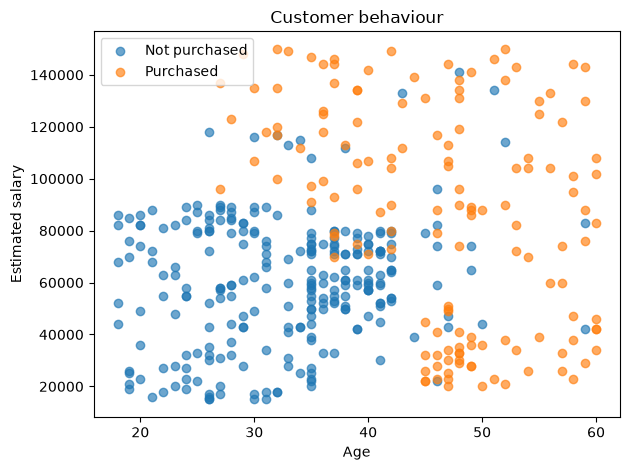

Train: (320, 2) | Test: (80, 2)


In [21]:
features = ['Age', 'EstimatedSalary']
X = df[features].copy()
y = df['Purchased'].astype(int)
for name, group in df.groupby('Purchased'):
    plt.scatter(group['Age'], group['EstimatedSalary'],
                label='Purchased' if name == 1 else 'Not purchased', alpha=0.65)
plt.xlabel('Age')
plt.ylabel('Estimated salary')
plt.legend()
plt.title('Customer behaviour')
plt.tight_layout()
plt.show()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

def make_model():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('nb', GaussianNB())
    ])

## 4. Huấn luyện Gaussian Naive Bayes cơ bản
Đây là mô hình trước tối ưu. Giữ riêng để so sánh với mô hình được chọn theo CV. Không dùng điểm test để chọn tham số.

In [22]:
base_model = make_model()
start = perf_counter()
base_model.fit(X_train, y_train)
base_fit_seconds = perf_counter() - start
print('Thời gian fit mô hình cơ bản:', round(base_fit_seconds, 5), 'giây')

Thời gian fit mô hình cơ bản: 0.00885 giây


## 5. Tối ưu var_smoothing bằng GridSearchCV
var_smoothing thêm một phần phương sai lớn nhất vào phương sai của các thuộc tính để tăng ổn định số học. Thử một dải giá trị trên train bằng CV phân tầng 5 fold, chọn theo accuracy. GridSearchCV tự refit cấu hình tốt nhất trên toàn bộ train

mean_test_score trong bảng GridSearchCV là điểm validation trong CV, không phải điểm của tập test 20% đã giữ riêng

Tham số tốt nhất: {'nb__var_smoothing': np.float64(1e-12)}
CV accuracy tốt nhất: 0.8938
Thời gian tìm tham số và refit: 0.6703 giây


,param_nb__var_smoothing,mean_train_score,mean_test_score,std_test_score
0,1.000000e-12,0.894531,0.893750,0.011693
1,1.000000e-11,0.894531,0.893750,0.011693
2,1.000000e-10,0.894531,0.893750,0.011693
3,1.000000e-09,0.894531,0.893750,0.011693
4,1.000000e-08,0.894531,0.893750,0.011693
5,1.000000e-07,0.894531,0.893750,0.011693
6,1.000000e-06,0.894531,0.893750,0.011693
7,1.000000e-05,0.894531,0.893750,0.011693
8,1.000000e-04,0.894531,0.893750,0.011693
9,1.000000e-03,0.893750,0.893750,0.011693


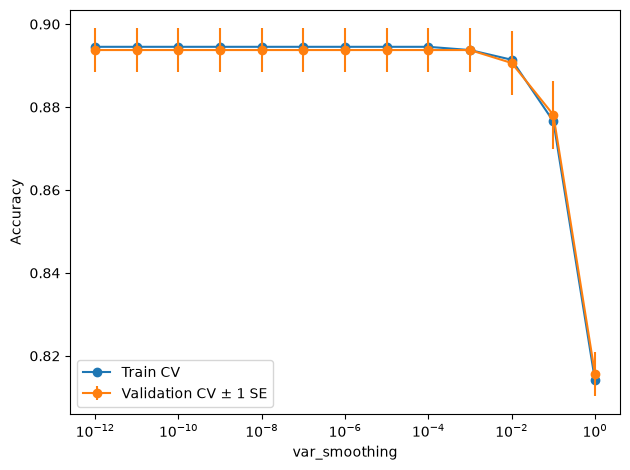

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    make_model(), {'nb__var_smoothing': np.logspace(-12, 0, 13)},
    scoring='accuracy', cv=cv, n_jobs=1, refit=True,
    return_train_score=True, error_score='raise')
start = perf_counter()
search.fit(X_train, y_train)
search_seconds = perf_counter() - start
best_model = search.best_estimator_
print('Tham số tốt nhất:', search.best_params_)
print('CV accuracy tốt nhất:', round(search.best_score_, 4))
print('Thời gian tìm tham số và refit:', round(search_seconds, 4), 'giây')
cv_results = pd.DataFrame(search.cv_results_)
display(cv_results[['param_nb__var_smoothing', 'mean_train_score',
                    'mean_test_score', 'std_test_score']])
x = cv_results['param_nb__var_smoothing'].astype(float)
plt.semilogx(x, cv_results['mean_train_score'], '-o', label='Train CV')
plt.errorbar(x, cv_results['mean_test_score'],
             yerr=cv_results['std_test_score'] / np.sqrt(cv.get_n_splits()),
             marker='o', label='Validation CV ± 1 SE')
plt.xscale('log')
plt.xlabel('var_smoothing')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Đánh giá trên tập test
Báo cáo accuracy, precision, recall, F1, ROC-AUC và ma trận nhầm lẫn. Lớp dương là Purchased = 1

Trong confusion matrix của scikit-learn, hàng là nhãn thật, cột là nhãn dự đoán. Thứ tự [0, 1] cho ma trận [[TN, FP], [FN, TP]]

,Train accuracy,Test accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Baseline,0.6438,0.6375,0.0000,0.0000,0.0000,0.5000
GaussianNB,0.8875,0.8750,0.8519,0.7931,0.8214,0.9493
GaussianNB tuned,0.8875,0.8750,0.8519,0.7931,0.8214,0.9493


Confusion matrix:
[[47  4]
 [ 6 23]]
               precision    recall  f1-score   support

Not purchased       0.89      0.92      0.90        51
    Purchased       0.85      0.79      0.82        29

     accuracy                           0.88        80
    macro avg       0.87      0.86      0.86        80
 weighted avg       0.87      0.88      0.87        80



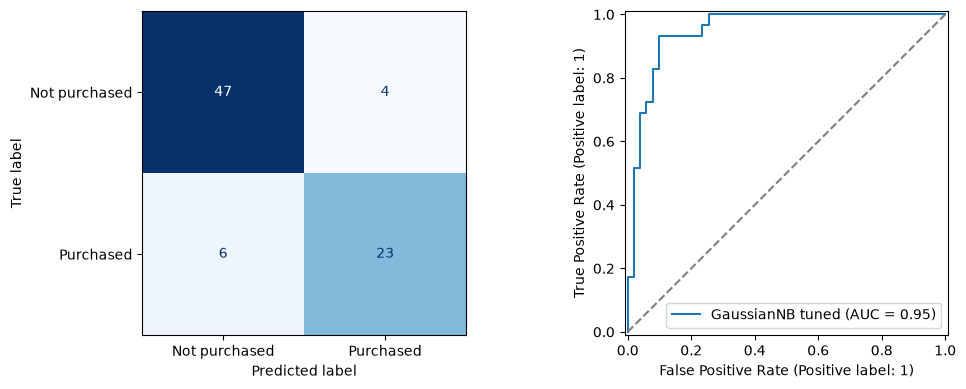

In [24]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
models = {'Baseline': baseline, 'GaussianNB': base_model, 'GaussianNB tuned': best_model}
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
        'Train accuracy': model.score(X_train, y_train),
        'Test accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)})
results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
print(classification_report(y_test, y_pred, labels=[0, 1],
      target_names=['Not purchased', 'Purchased'], zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1],
    display_labels=['Not purchased', 'Purchased'], cmap='Blues', colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name='GaussianNB tuned')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
plt.tight_layout()
plt.show()

## 7. Hiển thị ranh giới phân loại
Hình dùng đúng hai đầu vào của mô hình đã huấn luyện, tọa độ là tuổi và lương gốc. Pipeline tự xử lý chuẩn hóa khi dự đoán các điểm lưới. Điểm trên hình là dữ liệu test; màu nền là lớp mô hình dự đoán

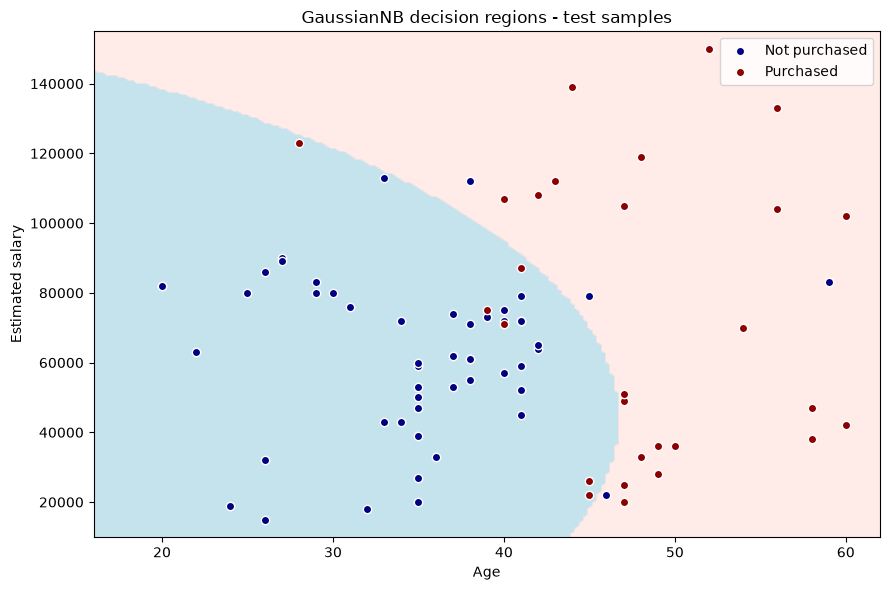

In [25]:
ages = np.linspace(X['Age'].min() - 2, X['Age'].max() + 2, 180)
salaries = np.linspace(X['EstimatedSalary'].min() - 5000,
                       X['EstimatedSalary'].max() + 5000, 180)
xx, yy = np.meshgrid(ages, salaries)
grid = pd.DataFrame({'Age': xx.ravel(), 'EstimatedSalary': yy.ravel()})
zz = best_model.predict(grid).reshape(xx.shape)
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['lightblue', 'mistyrose'], alpha=0.7)
for label, color in [(0, 'navy'), (1, 'darkred')]:
    group = X_test.loc[y_test == label]
    plt.scatter(group['Age'], group['EstimatedSalary'], color=color, edgecolor='white',
                label='Purchased' if label == 1 else 'Not purchased')
plt.xlabel('Age')
plt.ylabel('Estimated salary')
plt.title('GaussianNB decision regions - test samples')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Dự đoán cho khách hàng mới
Chỉ đưa hai cột được chọn vào mô hình. Xác suất Naive Bayes có thể chưa được hiệu chỉnh tốt; đây là ước lượng phục vụ thực hành.

In [26]:
new_customers = pd.DataFrame({'Age': [25, 45, 60], 'EstimatedSalary': [30000, 90000, 120000]})
new_results = new_customers.copy()
new_results['Predicted_Purchased'] = best_model.predict(new_customers)
new_results['Purchase_probability'] = best_model.predict_proba(new_customers)[:, 1]
display(new_results)

,Age,EstimatedSalary,Predicted_Purchased,Purchase_probability
0,25,30000,0,0.020124
1,45,90000,1,0.680975
2,60,120000,1,0.997833


## 9. Nhận xét kết quả
Chạy ô dưới để lấy các số liệu thực tế. So sánh mô hình cơ bản và mô hình tối ưu; tối ưu CV không đảm bảo điểm test cao hơn. Đánh giá khoảng cách train/test để nhận xét dấu hiệu quá khớp, nhưng không kết luận chỉ dựa trên một lần chia.

Giới hạn: dữ liệu nhỏ; giả định phân phối Gaussian và độc lập có điều kiện chỉ là xấp xỉ; mô hình chỉ sử dụng tuổi và lương. Có thể thử thêm giới tính bằng cách kết hợp thành phần categorical phù hợp, hoặc so sánh với cây quyết định trên cùng cách chia dữ liệu.

In [27]:
r = results.loc['GaussianNB tuned']
print(f'Train/Test: {len(X_train)}/{len(X_test)} mẫu.')
print(f'Accuracy test: {r["Test accuracy"]:.2%}; Precision: {r["Precision"]:.2%}; '
      f'Recall: {r["Recall"]:.2%}; F1: {r["F1"]:.4f}; ROC-AUC: {r["ROC-AUC"]:.4f}.')
print('Mô hình được chọn theo CV accuracy trên train, không chọn bằng điểm test.')

Train/Test: 320/80 mẫu.
Accuracy test: 87.50%; Precision: 85.19%; Recall: 79.31%; F1: 0.8214; ROC-AUC: 0.9493.
Mô hình được chọn theo CV accuracy trên train, không chọn bằng điểm test.
